# Chapitre 11 - Cours 4 : event sourcing, état et immutabilité

La capture des changements extrait un journal d'une base modifiable. L'**event sourcing**
va plus loin : il fait du **journal d'événements immuables** la source de vérité, et de
l'état courant une donnée dérivée. Ce notebook explore cette dualité entre état et flux,
ses avantages (audit, rejeu, vues multiples, concurrence simplifiée) et ses limites.

Il couvre la fin de la section *Databases and Streams* : *Event Sourcing* (*Deriving current state from the event log*, *Commands and events*) et *State, Streams, and Immutability*
(*Advantages of immutable events*, *Deriving several views from the same event log*,
*Concurrency control*, *Limitations of immutability*).

**Plan.**

1. L'état est l'intégrale d'un flux d'événements.
2. L'event sourcing : commandes, événements, rejeu et instantanés.
3. Les avantages des événements immuables.
4. Plusieurs vues à partir du même journal.
5. Contrôle de concurrence.
6. Les limites de l'immutabilité.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. L'état est l'intégrale d'un flux (section *State, Streams, and Immutability*)

Une base stocke habituellement l'**état courant**, la représentation la plus pratique pour
répondre aux requêtes ; l'état change, d'où les mises à jour et les suppressions. Mais
tout état qui change est le **résultat des événements** qui l'ont modifié : la liste des
places libres résulte des réservations traitées, le solde d'un compte des crédits et
débits, le graphique des temps de réponse d'un serveur de l'agrégation de chaque requête.
Même quand on fait puis défait quelque chose, le fait que ces événements ont eu lieu
reste vrai. État modifiable et journal d'événements immuables ne s'opposent donc pas :
ce sont **deux faces de la même pièce**.

En termes mathématiques, l'état est ce que l'on obtient en **intégrant** le flux
d'événements dans le temps, et le flux de changements ce que l'on obtient en **dérivant**
l'état : $\text{état}(t) = \text{état}(0) + \int_0^t \text{flux}(\tau)\, d\tau$. L'analogie
a ses limites (la dérivée seconde de l'état n'a guère de sens) mais c'est un bon point de
départ. Illustrons-la sur un compte bancaire.

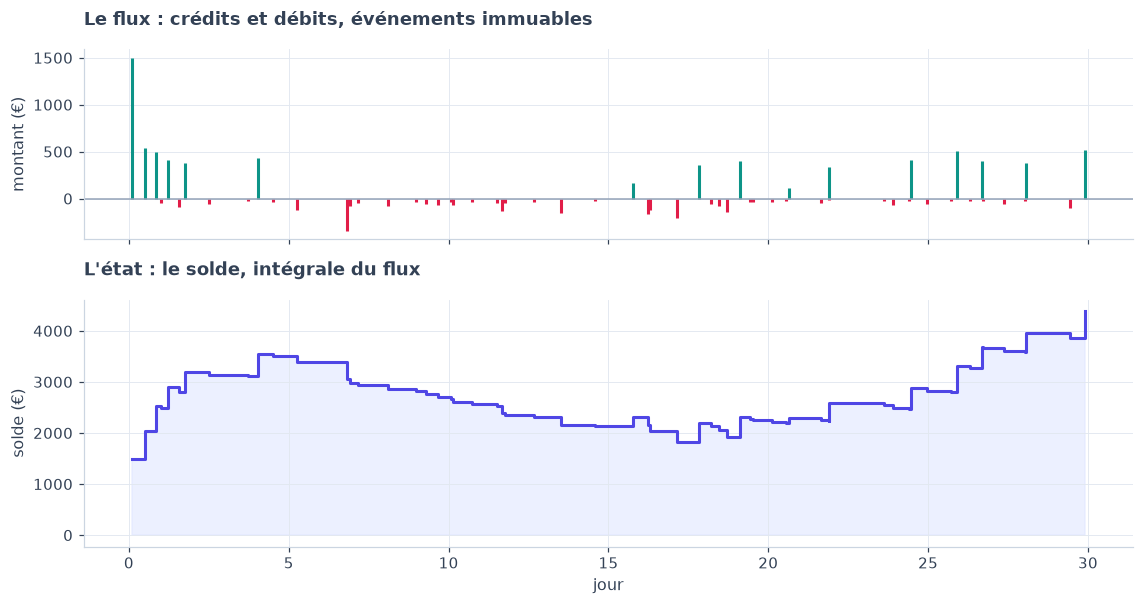

dériver le solde redonne exactement les événements : True


In [2]:
n = 60
t_ev = np.sort(rng.uniform(0, 30, n))
montants = np.where(rng.random(n) < 0.35, rng.normal(400, 120, n), -rng.gamma(2, 40, n)).round(0)
montants[0] = 1500
solde = np.cumsum(montants)                       # intégrer le flux donne l'état
retrouves = np.diff(np.concatenate([[0], solde]))  # dériver l'état redonne le flux
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10.5, 5.6), sharex=True, gridspec_kw=dict(height_ratios=[1, 1.3]))
ax.vlines(t_ev, 0, montants, color=np.where(montants > 0, TEAL, ROSE), lw=2)
ax.axhline(0, color=GRAY, lw=1)
ax.set_ylabel("montant (€)"); ax.set_title("Le flux : crédits et débits, événements immuables")
ax2.step(t_ev, solde, where="post", color=INDIGO)
ax2.fill_between(t_ev, solde, step="post", color=LIGHT[INDIGO], alpha=0.6)
ax2.set_ylabel("solde (€)"); ax2.set_xlabel("jour")
ax2.set_title("L'état : le solde, intégrale du flux")
plt.tight_layout(); plt.show()
print("dériver le solde redonne exactement les événements :", np.allclose(retrouves, montants))

Si l'on conserve durablement le journal des changements, l'état devient simplement
**reproductible**. En considérant le journal comme le système de référence et tout état
modifiable comme dérivé, il devient plus facile de raisonner sur les flux de données d'un
système. Jim Gray et Andreas Reuter le disaient dès 1992 : au fond, le journal contient
toute l'information, et la base de données (l'état « au bout du journal ») n'existe que
pour lire plus vite. La compaction du cours 3 fait le pont entre les deux : elle ne garde
que la dernière version de chaque enregistrement.

> **À retenir.** L'état est l'intégrale du flux d'événements, le flux la dérivée de l'état.
> Garder le journal rend l'état reproductible ; l'état n'est qu'un cache du journal.